## Problem 15
Add salt-and-pepper and Gaussian noise, then restore the image manually.

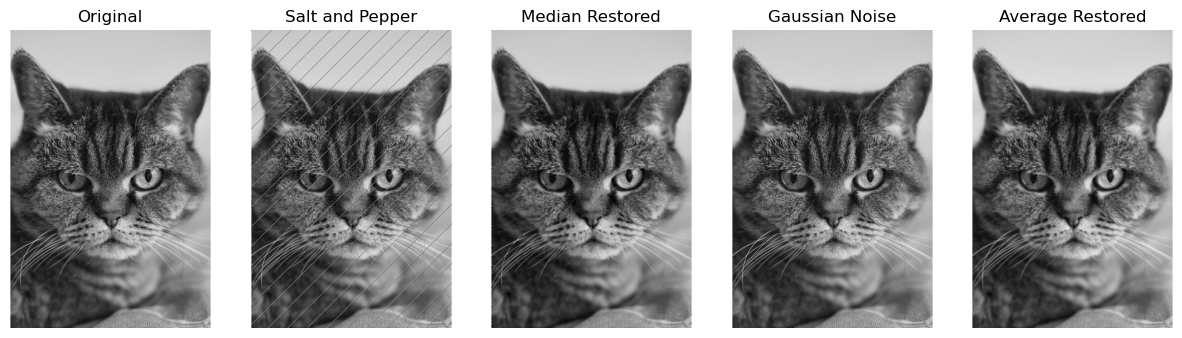

In [6]:
import cv2
import math
import matplotlib.pyplot as plt
import numpy as np

image = cv2.imread("cat.png", 0)
height, width = image.shape[:2]

# Add salt-and-pepper noise using a simple repeated pattern.
salt_pepper = image.copy()
for row in range(height):
    for col in range(width):
        if (row + col) % 50 == 0:
            salt_pepper[row, col] = 255
        elif (row + col) % 50 == 1:
            salt_pepper[row, col] = 0

# Add simple Gaussian-like noise using a sine formula.
gaussian_noise = image.copy()
for row in range(height):
    for col in range(width):
        noise = int(20 * math.sin(row + col))
        value = int(image[row, col]) + noise
        if value < 0: value = 0
        if value > 255: value = 255
        gaussian_noise[row, col] = value

def median_filter(source):
    result = np.zeros((height, width), dtype=np.uint8)
    for row in range(height):
        for col in range(width):
            values = []
            for r in range(row - 1, row + 2):
                for c in range(col - 1, col + 2):
                    rr = r
                    cc = c
                    if rr < 0: rr = 0
                    if rr >= height: rr = height - 1
                    if cc < 0: cc = 0
                    if cc >= width: cc = width - 1
                    values.append(int(source[rr, cc]))
            for i in range(8):
                for j in range(i + 1, 9):
                    if values[i] > values[j]:
                        values[i], values[j] = values[j], values[i]
            result[row, col] = values[4]
    return result

def average_filter(source):
    result = np.zeros((height, width), dtype=np.uint8)
    for row in range(height):
        for col in range(width):
            total = 0
            for r in range(row - 1, row + 2):
                for c in range(col - 1, col + 2):
                    rr = r
                    cc = c
                    if rr < 0: rr = 0
                    if rr >= height: rr = height - 1
                    if cc < 0: cc = 0
                    if cc >= width: cc = width - 1
                    total += int(source[rr, cc])
            result[row, col] = total // 9
    return result

restored_salt_pepper = median_filter(salt_pepper)
restored_gaussian = average_filter(gaussian_noise)

plt.figure(figsize=(15, 4))
plt.subplot(1, 5, 1)
plt.imshow(image, cmap="gray")
plt.title("Original")
plt.axis("off")

plt.subplot(1, 5, 2)
plt.imshow(salt_pepper, cmap="gray")
plt.title("Salt and Pepper")
plt.axis("off")

plt.subplot(1, 5, 3)
plt.imshow(restored_salt_pepper, cmap="gray")
plt.title("Median Restored")
plt.axis("off")

plt.subplot(1, 5, 4)
plt.imshow(gaussian_noise, cmap="gray")
plt.title("Gaussian Noise")
plt.axis("off")

plt.subplot(1, 5, 5)
plt.imshow(restored_gaussian, cmap="gray")
plt.title("Average Restored")
plt.axis("off")
plt.show()
